# Digital Finance Abstract BERTopic Analysis
  Input : CSV file (abstract + year)  
  Output:  
    1. Topic keyword table           topic_words_bertopic.csv  
    2. Document-topic assignments    document_topics.csv  
    3. Yearly topic-share heatmap    topics_evolution_bertopic.png  
    4. Intertopic distance map       interactive HTML
    5. Hierarchical topic tree       hierarchy_tree.html  

In [1]:
import os
os.environ["HF_ENDPOINT"] = "https://hf-mirror.com"   # 国内镜像

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import textwrap

In [2]:
# ============ Configuration (three knobs control the number of topics) ============
CSV_FILE     = "Data/digital_finance_aftercleaning.csv"
ABSTRACT_COL = "abstract"
YEAR_COL     = "year"
MIN_CLUSTER  = 6       
N_NEIGHBORS  = 8    
SEED = 42                         #Fixed Random Seed

In [3]:
# ============ 1. Load data + light cleaning (no nltk needed) ============
df = pd.read_csv(CSV_FILE)
df = df.dropna(subset=[ABSTRACT_COL, YEAR_COL])
df[ABSTRACT_COL] = df[ABSTRACT_COL].astype(str)

def clean_text(t):
    t = re.sub(r"http\S+|www\.\S+", " ", t)
    t = re.sub(r"[^a-zA-Z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip().lower()

df["clean"] = df[ABSTRACT_COL].apply(clean_text)
df = df[df["clean"].str.split().str.len() >= 15]   # Filter out overly short documents
docs = df["clean"].tolist()
timestamps = df[YEAR_COL].astype(int).tolist()
print(f"[1] Documents: {len(docs)} | Years: {min(timestamps)}-{max(timestamps)}")

[1] Documents: 194 | Years: 2019-2026


In [4]:
# ============ 2. Embeddings (same as v1, verified working) ============
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = embedding_model.encode(docs, show_progress_bar=True, batch_size=64)
print(f"[2] Embeddings: {embeddings.shape}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

[2] Embeddings: (194, 384)


In [5]:
# ============ 3. Sub-models (all topic-count adjustments live here) ============
umap_model = UMAP(
    n_neighbors=N_NEIGHBORS,     # ★ Lowered
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=SEED,
)
hdbscan_model = HDBSCAN(
    min_cluster_size=MIN_CLUSTER,       # ★ Lowered
    metric="euclidean",
    cluster_selection_method="leaf",    # ★ eom -> leaf: stop merging big clusters aggressively
    prediction_data=True,
)

# Note: v1 used CountVectorizer(min_df=5, max_features=4000). If it raised
# max_df/min_df errors back then, keep min_df=1; here we simplify and add
# stopwords to improve vocabulary quality.
domain_stopwords = [
    "paper", "study", "studies", "research", "using", "used", "use", "based",
    "propose", "proposed", "article", "result", "results", "finding", "findings",
    "show", "shows", "examine", "examined", "investigate", "explore", "aim",
    "however", "also", "many", "several", "various", "different", "significant",
    "important", "provide", "suggest", "demonstrate", "find", "present", "novel",
    "new", "existing", "recent", "literature", "empirical", "analysis", "approach",
    "method", "methods", "model", "models", "framework", "evidence", "effect",
    "effects", "impact", "impacts", "data", "sample", "test", "measure", "level",
    "financial", "finance", "digital", "market", "markets", "economic", "economy",
    "sector", "industry", "firm", "firms", "china", "chinese", "global", "country",
    "countries", "development", "year", "years", "time", "value", "change", "increase",
    "function", "basis", "points", "during", "periods", "insight", "into", "that",
    "are", "the", "and", "of", "to", "in", "this", "on", "regulatory", "by", "for",
    "at", "we", "is", "with", "as", "an", "from", "our", "short", "long", "can", "be",
]
vectorizer_model = CountVectorizer(
    stop_words=domain_stopwords,
    ngram_range=(2, 3),
    min_df=1,           # Few documents per topic, must be 1
    max_features=8000,
)

In [6]:
# ============ 4. Train ============
topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    calculate_probabilities=False,
    verbose=True,
)
topics, probs = topic_model.fit_transform(docs, embeddings)

n_topics = len(set(topics) - {-1})
outlier_pct = (np.array(topics) == -1).mean()
print(f"\n[3] Topics: {n_topics} | Outliers: {outlier_pct:.1%}")

2026-10-17 12:54:12,312 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-17 12:54:25,420 - BERTopic - Dimensionality - Completed ✓
2026-10-17 12:54:25,422 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-17 12:54:25,431 - BERTopic - Cluster - Completed ✓
2026-10-17 12:54:25,435 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-17 12:54:25,558 - BERTopic - Representation - Completed ✓



[3] Topics: 10 | Outliers: 12.4%


In [7]:
# ============ 5. Topic word table ============
topic_info = topic_model.get_topic_info()
print(len(topic_info))
print(topic_info[["Topic", "Count", "Name"]].head(25).to_string())

rows = []
for t in topic_info["Topic"]:
    if t == -1:
        continue
    rows.append({
        "Topic": t,
        "Count": int(topic_info.loc[topic_info.Topic == t, "Count"].iloc[0]),
        "Top10": ", ".join(w for w, _ in topic_model.get_topic(t)[:10]),
    })
words_df = pd.DataFrame(rows).sort_values("Count", ascending=False)
words_df.to_csv("Result/BERTopic/topic_words.csv", index=False, encoding="utf-8-sig")
df[["year"]].assign(topic=topics).to_csv("Result/BERTopic/document_topics.csv",
                                         index=False, encoding="utf-8-sig")

11
    Topic  Count                                                                              Name
0      -1     24               -1_crypto loans_trading strategies_flexible majority_majority rules
1       0     28       0_corporate governance_money laundering_soft information_variance explained
2       1     27            1_neural network_machine learning_reinforcement learning_deep learning
3       2     21     2_smart contracts_blockchain technology_distributed ledger_programmable money
4       3     20                 3_safe haven_risk management_metaverse tokens_volatility dynamics
5       4     18                       4_bitcoin price_exchange rate_bitcoin prices_bitcoin dollar
6       5     16                5_investor sentiment_social media_stock returns_sentiment measures
7       6     13  6_liquidity provision_concentrated liquidity_constant makers_liquidity providers
8       7     11                       7_machine learning_credit risk_interest rate_credit scoring
9      

8it [00:00, 39.70it/s]


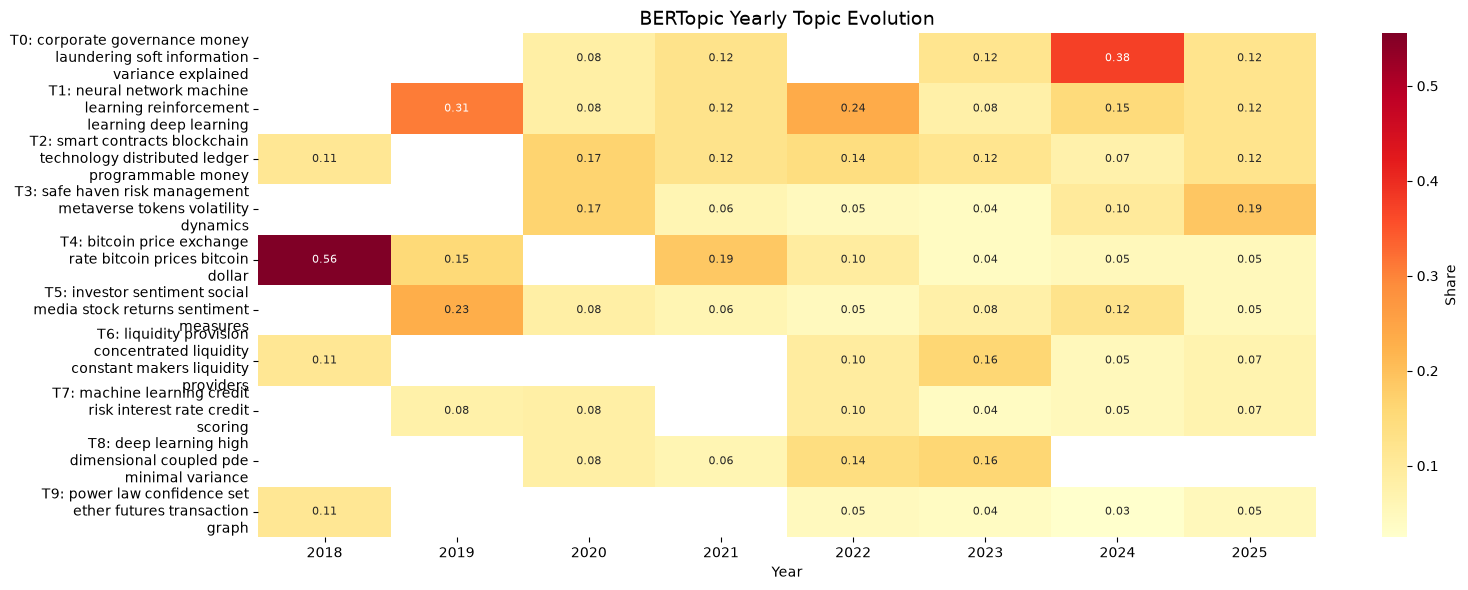

In [8]:
# ============ 6. Yearly evolution heatmap ============
tot = topic_model.topics_over_time(
    docs, timestamps, global_tuning=True, evolution_tuning=True,
    datetime_format="%Y", nr_bins=len(set(timestamps)),
)
tot["year"] = tot["Timestamp"].astype(int)
pivot = tot.pivot_table(index="Topic", columns="year",
                        values="Frequency", aggfunc="sum")
pivot = pivot.div(pivot.sum(axis=0), axis=1).drop(index=-1, errors="ignore")

label_map = {
    t: textwrap.fill(f"T{t}: " + " ".join(w for w, _ in topic_model.get_topic(t)[:4]), width=30)
    for t in pivot.index
}
pivot.index = [label_map.get(t, f"T{t}") for t in pivot.index]

plt.figure(figsize=(16, max(6, 0.5 * len(pivot))))
sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt=".2f",
            annot_kws={"size": 8}, cbar_kws={"label": "Share"})
plt.title("BERTopic Yearly Topic Evolution", fontsize=14)
plt.xlabel("Year")
plt.ylabel("")
plt.tight_layout()
plt.savefig("Result/BERTopic/topics_evolution.png", dpi=200, bbox_inches="tight")

In [9]:
# ============ 7. Intertopic distance map ============
fig = topic_model.visualize_topics(
    top_n_topics=None,      # Plot only the N most frequent topics; None = all
    use_ctfidf=False,       # Default: joint embedding + c-TF-IDF; True forces c-TF-IDF only
    custom_labels=False,    # True: use user-defined topic names instead of "T0/T1..."
    width=650, height=650,
)
fig.write_html("Result/BERTopic/intertopic_distance_map.html")   # Save as HTML to keep interactivity

In [10]:
# ============ 8. Hierarchical topic tree (optimized) ============
hierarchical_topics = topic_model.hierarchical_topics(docs)

# ---- 1) long label ----
custom_labels = {}
for t in topic_model.get_topic_info()["Topic"]:
    if t == -1:
        continue
    words = [w for w, _ in topic_model.get_topic(t)[:4]]
    custom_labels[t] = f"T{t}: " + ", ".join(words)   # 不再用 wrap，保持一行

topic_model.set_topic_labels(custom_labels)

# ---- 2) topic label 700px，figure 300px ----
fig = topic_model.visualize_hierarchy(
    hierarchical_topics=hierarchical_topics,
    top_n_topics=30,
    custom_labels=True,
    width=1020,
    height=900,
)

fig.update_layout(
    margin=dict(l=700, r=20, t=60, b=40),
    font=dict(size=13),
    title_font=dict(size=18),
)

# ---- 3) axis 0.8 ----
x_max = fig.layout.xaxis.range[1] if fig.layout.xaxis.range else None
fig.update_xaxes(
    range=[0.8, x_max] if x_max else [0.8, 1.1],   
    title_font=dict(size=13),
)
fig.update_yaxes(tickfont=dict(size=13), title=None)

fig.write_html("Result/BERTopic/hierarchy_tree.html")


100%|██████████| 9/9 [00:00<00:00, 296.53it/s]
